In [16]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.4 MB/s eta 0:00:00


In [15]:
from torch.cuda import is_available
import torch
import ultralytics

print("Torch version: "+ torch.__version__)
print("Ultralytics version: "+ ultralytics.__version__)
print("GPU available: "+ str(torch.cuda.is_available()))

if torch.cuda.is_available():
  print("GPU name: "+ torch.cuda.get_device_name(0))

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
from ultralytics import YOLO

model=YOLO("yolov8n.pt")

print("Model loaded succesfully")

Model loaded succesfully



Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 12.0ms
Speed: 2.3ms preprocess, 12.0ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 480)


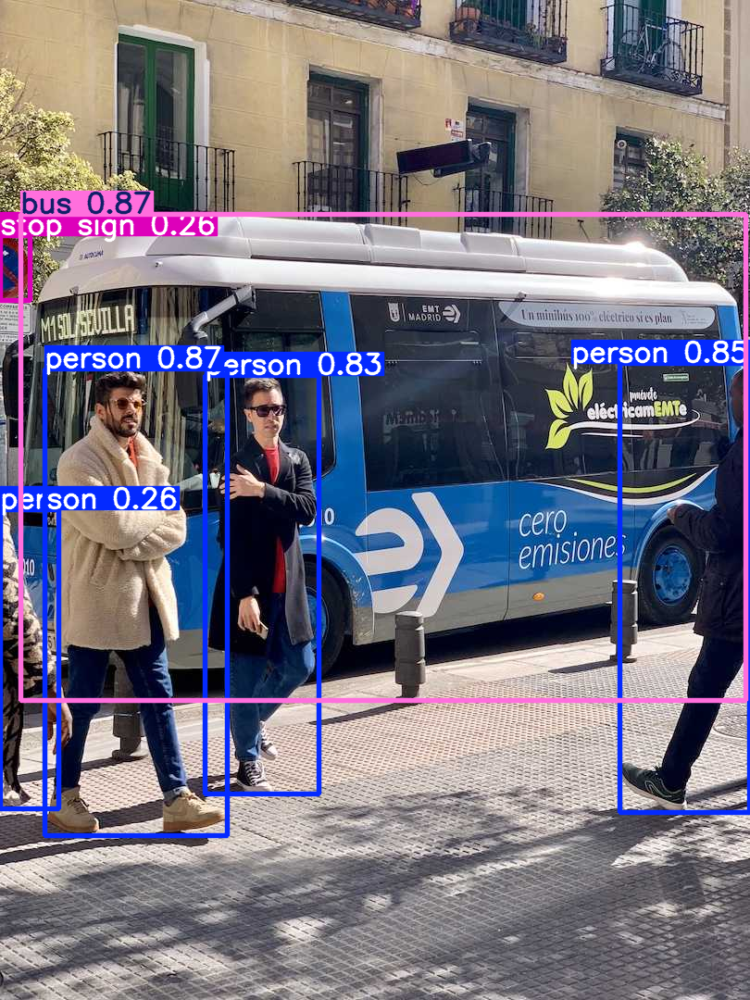

In [ ]:
from IPython.display import display
from PIL import Image

results = model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    conf=0.25
)

annotated_image= results[0].plot()
display(Image.fromarray(annotated_image[:, :, ::-1]))


In [ ]:

for result in results:
    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        coordinates = box.xyxy[0].tolist()

        print(
            f"Class: {model.names[class_id]}, "
            f"Confidence: {confidence:.2%}, "
            f"Box: {coordinates}"
        )


Class: bus, Confidence: 87.34%, Box: [22.87126922607422, 231.27731323242188, 805.002685546875, 756.8404541015625]
Class: person, Confidence: 86.57%, Box: [48.55049133300781, 398.55218505859375, 245.34555053710938, 902.7026977539062]
Class: person, Confidence: 85.28%, Box: [669.472900390625, 392.18597412109375, 809.7201538085938, 877.0354614257812]
Class: person, Confidence: 82.52%, Box: [221.51730346679688, 405.79864501953125, 344.97064208984375, 857.53662109375]
Class: person, Confidence: 26.11%, Box: [0.0, 550.5250244140625, 63.0069694519043, 873.4429321289062]
Class: stop sign, Confidence: 25.51%, Box: [0.05817067623138428, 254.45938110351562, 32.557411193847656, 324.8741760253906]


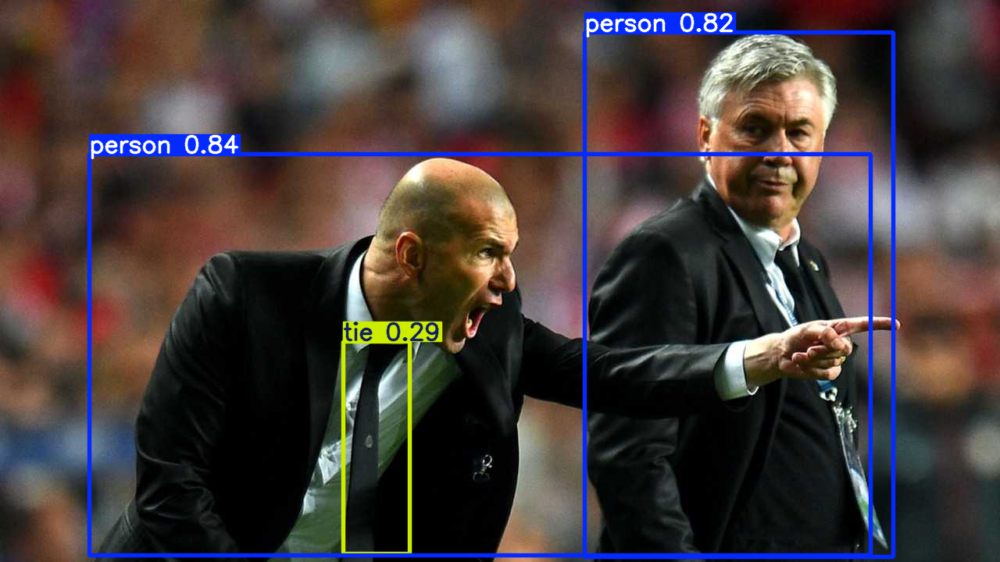

In [ ]:
result = model.predict(
    source="https://ultralytics.com/images/zidane.jpg",
    conf=0.25,
    verbose=False
)[0]

display(Image.fromarray(result.plot()[:, :, ::-1]))

In [1]:
from google.colab import files

uploaded = files.upload()

Saving YOLO Waste Detection.v1-small-classes-refactoring-done.yolov8.zip to YOLO Waste Detection.v1-small-classes-refactoring-done.yolov8.zip


In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/SmartWasteDetection"
)

PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)

Project folder: /content/drive/MyDrive/SmartWasteDetection


In [4]:
import shutil

shutil.copy2(
    "/content/YOLO Waste Detection.v1-small-classes-refactoring-done.yolov8.zip",
    PROJECT_DIR / "waste_dataset.zip"
)

PosixPath('/content/drive/MyDrive/SmartWasteDetection/waste_dataset.zip')

In [5]:
import zipfile
from pathlib import Path

zip_files = list(Path("/content").glob("*.zip"))

if not zip_files:
    raise FileNotFoundError("Upload your dataset ZIP first.")

zip_path = zip_files[0]
dataset_dir = Path("/content/waste_dataset")
dataset_dir.mkdir(exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(dataset_dir)

print("Dataset extracted to:", dataset_dir)

Dataset extracted to: /content/waste_dataset


In [6]:
from pathlib import Path
import yaml

yaml_files = list(dataset_dir.rglob("data.yaml"))

if not yaml_files:
    print("No data.yaml found. We will inspect the folder structure.")
else:
    yaml_path = yaml_files[0]

    with open(yaml_path, "r") as f:
        data = yaml.safe_load(f)

    print("Configuration:", yaml_path)
    print("Classes:", data.get("names"))
    print("Training path:", data.get("train"))
    print("Validation path:", data.get("val"))
    print("Test path:", data.get("test"))

Configuration: /content/waste_dataset/data.yaml
Classes: ['Aluminum can', 'Cardboard', 'Container for household chemicals', 'Glass bottle', 'Organic', 'Paper', 'Plastic bag', 'Plastic bottle', 'Plastic cup', 'Tin']
Training path: ../train/images
Validation path: ../valid/images
Test path: ../test/images


In [7]:
from pathlib import Path
import yaml

yaml_path = Path("/content/waste_dataset/data.yaml")

with open(yaml_path, "r") as f:
    config = yaml.safe_load(f)

print("Dataset configuration:")
print(config)

print("\nFolders inside /content:")
for p in Path("/content").iterdir():
    if p.is_dir():
        print(p)

print("\nFolders inside the dataset:")
for p in Path("/content/waste_dataset").rglob("*"):
    if p.is_dir() and p.name in [
        "images", "labels", "train", "valid", "test"
    ]:
        print(p)

Dataset configuration:
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 10, 'names': ['Aluminum can', 'Cardboard', 'Container for household chemicals', 'Glass bottle', 'Organic', 'Paper', 'Plastic bag', 'Plastic bottle', 'Plastic cup', 'Tin'], 'roboflow': {'workspace': 'simpledimploma', 'project': 'yolo-waste-detection-9ebbc', 'version': 1, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/simpledimploma/yolo-waste-detection-9ebbc/dataset/1'}}

Folders inside /content:
/content/.config
/content/waste_dataset
/content/drive
/content/sample_data

Folders inside the dataset:
/content/waste_dataset/train
/content/waste_dataset/valid
/content/waste_dataset/test
/content/waste_dataset/train/images
/content/waste_dataset/train/labels
/content/waste_dataset/valid/images
/content/waste_dataset/valid/labels
/content/waste_dataset/test/images
/content/waste_dataset/test/labels


In [8]:

from pathlib import Path
from collections import Counter
import shutil
import yaml

# Original dataset
SOURCE = Path("/content/waste_dataset")

# New filtered dataset
DEST = Path("/content/waste_four_classes")

# Original class ID -> new class ID
CLASS_MAP = {
    0: 0,  # Aluminum can
    1: 1,  # Cardboard
    5: 2,  # Paper
    7: 3,  # Plastic bottle
}

CLASS_NAMES = [
    "Aluminum can",
    "Cardboard",
    "Paper",
    "Plastic bottle",
]

SPLITS = ["train", "valid", "test"]

# Start with a fresh output folder
if DEST.exists():
    shutil.rmtree(DEST)

stats = {}

for split in SPLITS:
    image_dir = SOURCE / split / "images"
    label_dir = SOURCE / split / "labels"

    out_images = DEST / split / "images"
    out_labels = DEST / split / "labels"

    out_images.mkdir(parents=True, exist_ok=True)
    out_labels.mkdir(parents=True, exist_ok=True)

    kept = 0
    no_target = 0
    missing_labels = 0
    bad_annotations = 0
    class_counts = Counter()

    for image_path in image_dir.iterdir():
        if not image_path.is_file():
            continue

        label_path = label_dir / f"{image_path.stem}.txt"

        if not label_path.exists():
            missing_labels += 1
            continue

        new_lines = []

        for line in label_path.read_text().splitlines():
            if not line.strip():
                continue

            parts = line.split()

            try:
                original_id = int(parts[0])
                if original_id < 0 or original_id >= 10:
                    raise ValueError("Invalid class ID")
            except (ValueError, IndexError):
                bad_annotations += 1
                continue

            if original_id in CLASS_MAP:
                parts[0] = str(CLASS_MAP[original_id])
                new_lines.append(" ".join(parts))
                class_counts[CLASS_MAP[original_id]] += 1

        # Keep only images containing at least one target object
        if not new_lines:
            no_target += 1
            continue

        shutil.copy2(image_path, out_images / image_path.name)
        (out_labels / label_path.name).write_text(
            "\n".join(new_lines) + "\n"
        )
        kept += 1

    stats[split] = {
        "images_kept": kept,
        "images_without_target": no_target,
        "missing_label_files": missing_labels,
        "invalid_annotations": bad_annotations,
        "objects_per_class": dict(class_counts),
    }

# Write a configuration for the new dataset
new_config = {
    "path": str(DEST),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": len(CLASS_NAMES),
    "names": CLASS_NAMES,
}

(DEST / "data.yaml").write_text(
    yaml.safe_dump(new_config, sort_keys=False)
)

print("Dataset preparation complete!\n")

for split, info in stats.items():
    print(f"--- {split.upper()} ---")
    for key, value in info.items():
        print(f"{key}: {value}")
    print()

print("New configuration:", DEST / "data.yaml")
print("Class names:", CLASS_NAMES)


Dataset preparation complete!

--- TRAIN ---
images_kept: 6390
images_without_target: 4878
missing_label_files: 0
invalid_annotations: 0
objects_per_class: {2: 1167, 3: 2793, 0: 3846, 1: 1383}

--- VALID ---
images_kept: 603
images_without_target: 469
missing_label_files: 0
invalid_annotations: 0
objects_per_class: {0: 404, 3: 238, 1: 134, 2: 98}

--- TEST ---
images_kept: 313
images_without_target: 230
missing_label_files: 0
invalid_annotations: 0
objects_per_class: {1: 75, 0: 192, 3: 135, 2: 52}

New configuration: /content/waste_four_classes/data.yaml
Class names: ['Aluminum can', 'Cardboard', 'Paper', 'Plastic bottle']


In [9]:

from pathlib import Path
import yaml

dataset = Path("/content/waste_four_classes")

with open(dataset / "data.yaml", "r") as f:
    config = yaml.safe_load(f)

print("Number of classes:", config["nc"])
print("Class names:", config["names"])

for split in ["train", "valid", "test"]:
    images = list((dataset / split / "images").glob("*"))
    labels = list((dataset / split / "labels").glob("*.txt"))

    print(
        f"{split}: {len(images)} images, "
        f"{len(labels)} label files"
    )

# Check that every retained annotation uses class IDs 0–3
invalid = []

for label in dataset.rglob("labels/*.txt"):
    for line in label.read_text().splitlines():
        if line.strip():
            class_id = int(line.split()[0])
            if class_id not in range(4):
                invalid.append((str(label), class_id))

print("Invalid class IDs:", len(invalid))


Number of classes: 4
Class names: ['Aluminum can', 'Cardboard', 'Paper', 'Plastic bottle']
train: 6390 images, 6390 label files
valid: 603 images, 603 label files
test: 313 images, 313 label files
Invalid class IDs: 0


In [10]:

from pathlib import Path
from collections import Counter

dataset = Path("/content/waste_four_classes")

class_names = [
    "Aluminum can",
    "Cardboard",
    "Paper",
    "Plastic bottle",
]

for split in ["train", "valid", "test"]:
    counts = Counter()
    label_dir = dataset / split / "labels"

    for label_file in label_dir.glob("*.txt"):
        for line in label_file.read_text().splitlines():
            if line.strip():
                class_id = int(line.split()[0])
                counts[class_id] += 1

    print(f"\n{split.upper()} object counts:")
    for class_id, name in enumerate(class_names):
        print(f"{name}: {counts[class_id]}")



TRAIN object counts:
Aluminum can: 3846
Cardboard: 1383
Paper: 1167
Plastic bottle: 2793

VALID object counts:
Aluminum can: 404
Cardboard: 134
Paper: 98
Plastic bottle: 238

TEST object counts:
Aluminum can: 192
Cardboard: 75
Paper: 52
Plastic bottle: 135


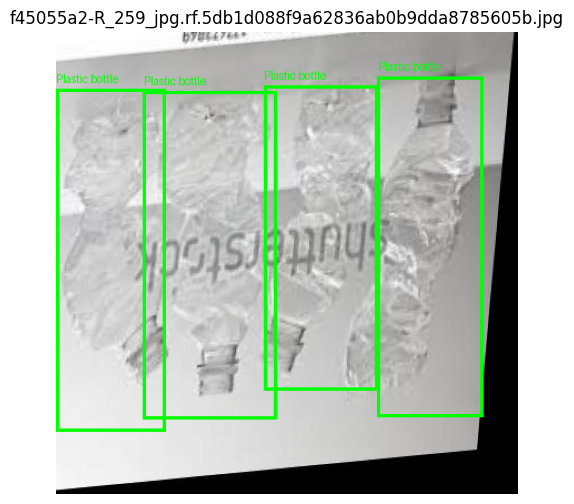

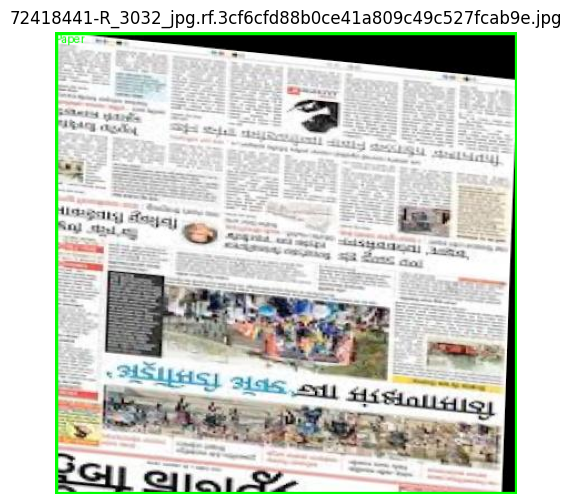

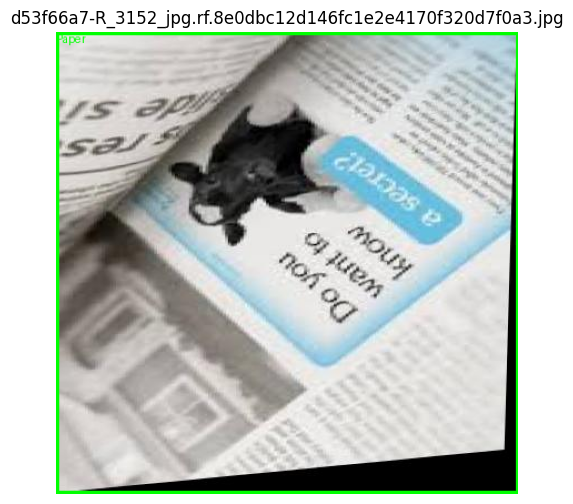

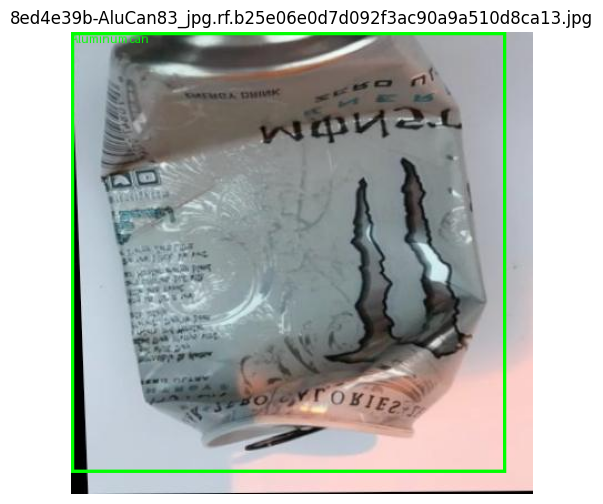

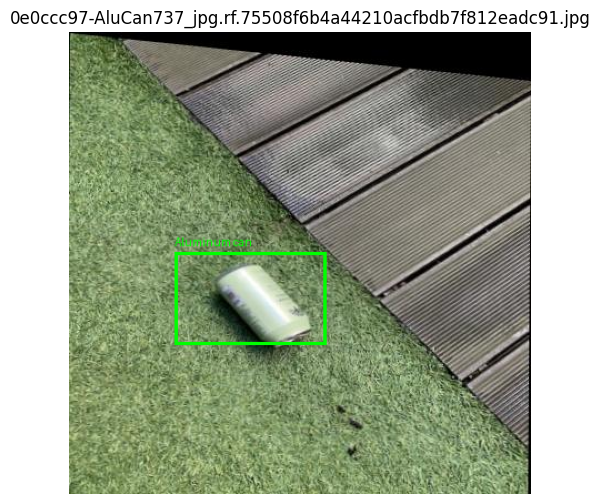

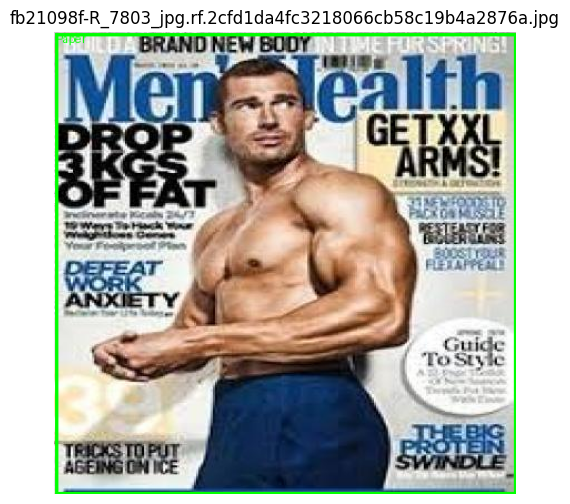

In [12]:

from pathlib import Path
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import random

dataset = Path("/content/waste_four_classes")
split = "train"

image_dir = dataset / split / "images"
label_dir = dataset / split / "labels"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
image_paths = [
    p for p in image_dir.iterdir()
    if p.suffix.lower() in image_extensions
]

# Select six reproducible random images
random.seed(42)
samples = random.sample(image_paths, min(6, len(image_paths)))

class_names = [
    "Aluminum can",
    "Cardboard",
    "Paper",
    "Plastic bottle",
]

for image_path in samples:
    label_path = label_dir / f"{image_path.stem}.txt"

    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    img_w, img_h = image.size

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            if not line.strip():
                continue

            parts = line.split()
            class_id = int(parts[0])
            x_center, y_center, width, height = map(float, parts[1:5])

            # Convert normalized YOLO coordinates to pixels
            x1 = (x_center - width / 2) * img_w
            y1 = (y_center - height / 2) * img_h
            x2 = (x_center + width / 2) * img_w
            y2 = (y_center + height / 2) * img_h

            draw.rectangle(
                [x1, y1, x2, y2],
                outline="lime",
                width=3
            )

            draw.text(
                (x1, max(0, y1 - 15)),
                class_names[class_id],
                fill="lime"
            )

    plt.figure(figsize=(8, 6))
    plt.imshow(image)
    plt.title(image_path.name)
    plt.axis("off")
    plt.show()


In [13]:

from pathlib import Path

dataset = Path("/content/waste_four_classes")
errors = []

for split in ["train", "valid", "test"]:
    label_dir = dataset / split / "labels"

    for label_file in label_dir.glob("*.txt"):
        for line_num, line in enumerate(
            label_file.read_text().splitlines(), start=1
        ):
            if not line.strip():
                continue

            parts = line.split()

            try:
                if len(parts) != 5:
                    raise ValueError("Expected five values")

                class_id = int(parts[0])
                x, y, w, h = map(float, parts[1:])

                if class_id not in range(4):
                    raise ValueError("Invalid class ID")

                if not all(0 <= v <= 1 for v in [x, y, w, h]):
                    raise ValueError("Coordinates outside [0, 1]")

                if w <= 0 or h <= 0:
                    raise ValueError("Non-positive box dimensions")

                if x - w / 2 < -1e-6 or x + w / 2 > 1 + 1e-6:
                    raise ValueError("Box exceeds horizontal image bounds")

                if y - h / 2 < -1e-6 or y + h / 2 > 1 + 1e-6:
                    raise ValueError("Box exceeds vertical image bounds")

            except (ValueError, OverflowError) as e:
                errors.append(
                    f"{label_file.name}, line {line_num}: {e}"
                )

print("Invalid annotations:", len(errors))
for error in errors[:20]:
    print(error)


Invalid annotations: 0


In [17]:

from pathlib import Path
import torch
import yaml
from ultralytics import YOLO

# Dataset configuration
DATA_YAML = Path("/content/waste_four_classes/data.yaml")

assert DATA_YAML.exists(), "Dataset configuration not found!"

with open(DATA_YAML, "r") as f:
    config = yaml.safe_load(f)

print("Classes:", config["names"])
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    device = 0
else:
    print("No GPU detected. Training on CPU.")
    device = "cpu"

# Load pretrained weights
model = YOLO("yolov8n.pt")

# Fine-tune on our four-class dataset
results = model.train(
    data=str(DATA_YAML),
    epochs=50,
    imgsz=640,
    batch=16,
    patience=10,
    device=device,
    workers=2,
    seed=42,
    project="/content/runs/detect",
    name="smart_waste_v1",
    plots=True,
    save=True
)

print("Training finished!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Classes: ['Aluminum can', 'Cardboard', 'Paper', 'Plastic bottle']
GPU available: True
GPU: Tesla T4
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/waste_four_classes/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, e

In [18]:

from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")

best_model = Path(
    "/content/runs/detect/smart_waste_v1/weights/best.pt"
)

project_dir = Path(
    "/content/drive/MyDrive/SmartWasteDetection"
)

project_dir.mkdir(parents=True, exist_ok=True)

if best_model.exists():
    destination = project_dir / "smart_waste_v1_best.pt"
    shutil.copy2(best_model, destination)
    print("Best model saved to:", destination)
else:
    print("Best model checkpoint not found. Check the training output.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Best model saved to: /content/drive/MyDrive/SmartWasteDetection/smart_waste_v1_best.pt


In [19]:

from ultralytics import YOLO
from pathlib import Path

model_path = Path(
    "/content/drive/MyDrive/SmartWasteDetection/"
    "smart_waste_v1_best.pt"
)

model = YOLO(str(model_path))

metrics = model.val(
    data="/content/waste_four_classes/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    plots=True
)

print(f"Test mAP50:    {metrics.box.map50:.4f}")
print(f"Test mAP50-95: {metrics.box.map:.4f}")
print(f"Test precision: {metrics.box.mp:.4f}")
print(f"Test recall:    {metrics.box.mr:.4f}")



Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1048.1±540.0 MB/s, size: 24.5 KB)
val: Scanning /content/waste_four_classes/test/labels... 313 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 313/313 2.0Kit/s 0.2s
val: New cache created: /content/waste_four_classes/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 20/20 4.3it/s 4.6s
                   all        313        454      0.858      0.799      0.853      0.609
          Aluminum can        158        192      0.898      0.906      0.951      0.631
             Cardboard         61         75      0.858      0.933      0.952      0.699
                 Paper         52         52      0.911      0.904      0.954      0.804
        Plastic bottle         42        135      0.764      0.4

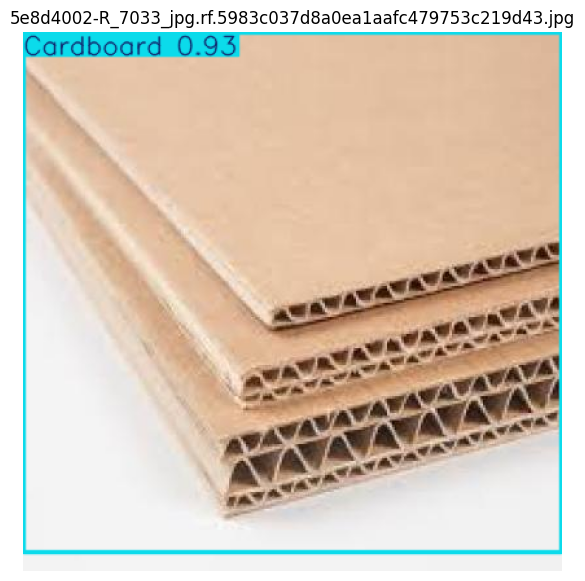

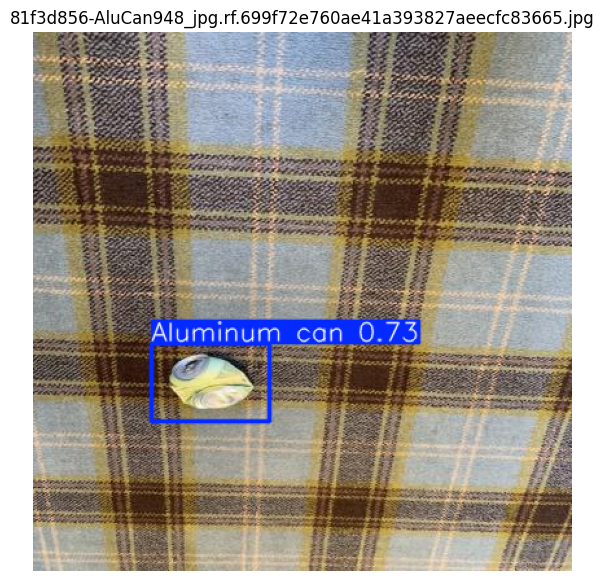

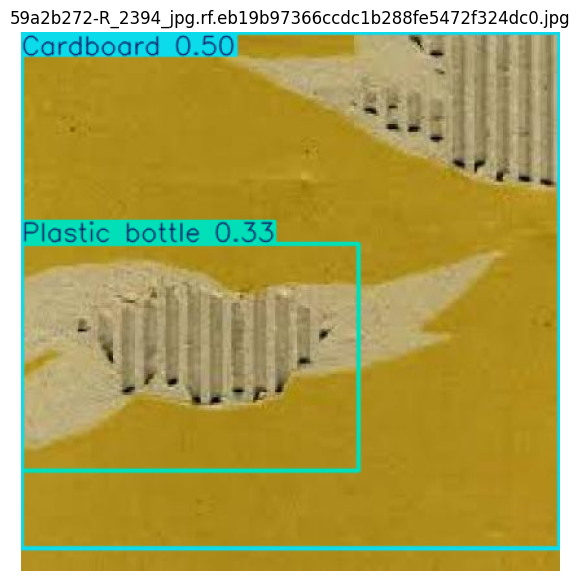

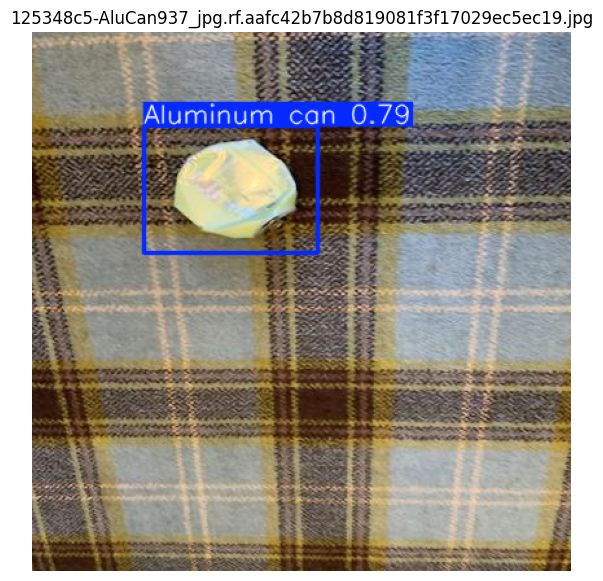

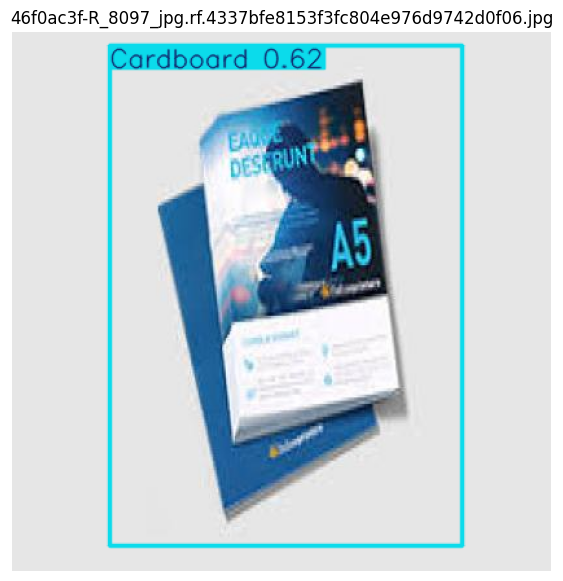

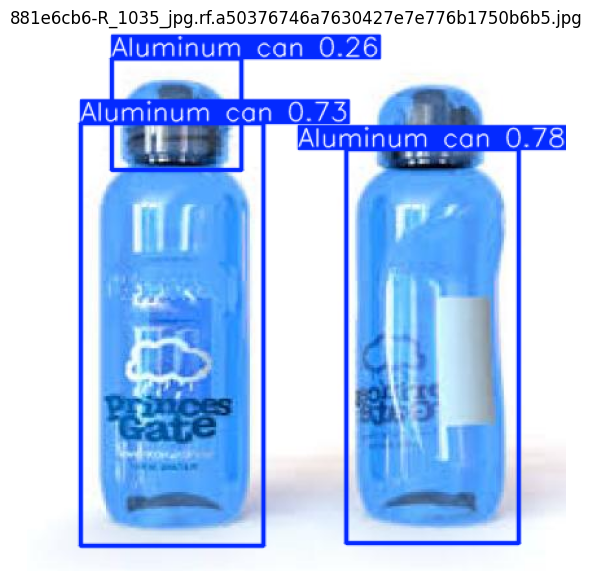

In [23]:
from ultralytics import YOLO
from pathlib import Path
import random
import matplotlib.pyplot as plt

model = YOLO(
    "/content/drive/MyDrive/SmartWasteDetection/"
    "smart_waste_v1_best.pt"
)

test_dir = Path("/content/waste_four_classes/test/images")
images = [
    p for p in test_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
]

random.seed(41)
samples = random.sample(images, min(6, len(images)))

for image_path in samples:
    result = model.predict(
        source=str(image_path),
        conf=0.25,
        verbose=False
    )[0]

    annotated = result.plot()

    plt.figure(figsize=(10, 7))
    plt.imshow(annotated[:, :, ::-1])
    plt.title(image_path.name)
    plt.axis("off")
    plt.show()

Bottle-containing test images selected: 6


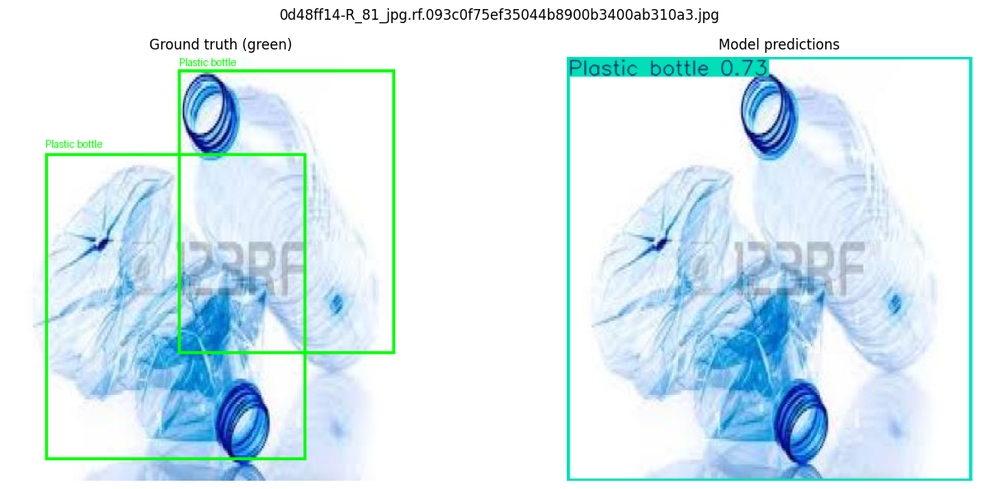

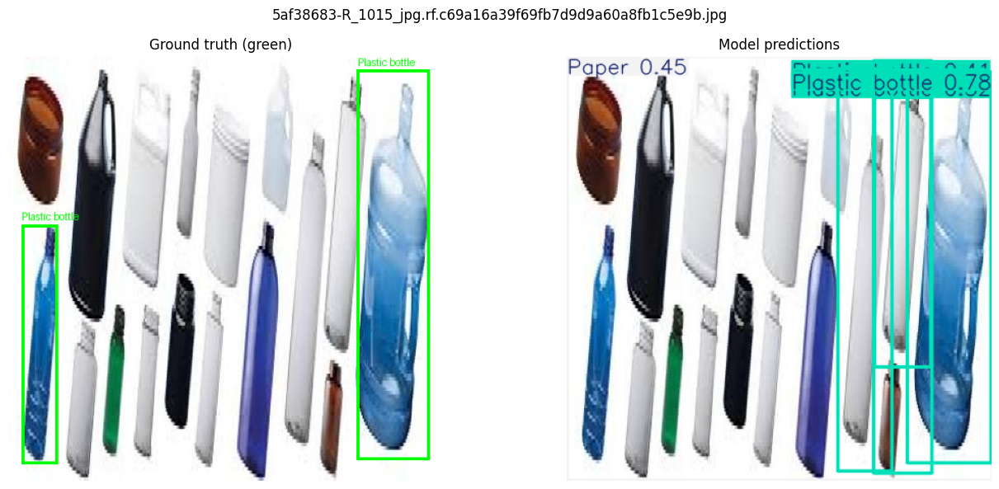

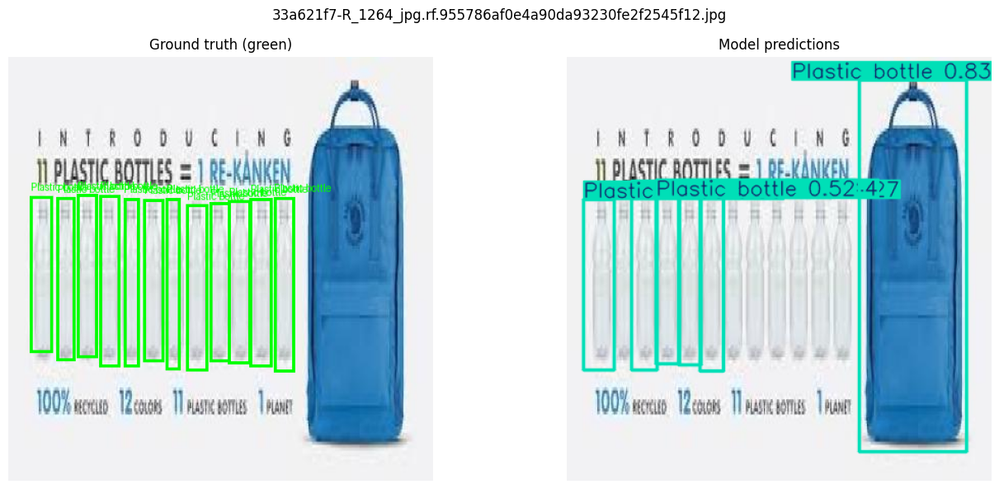

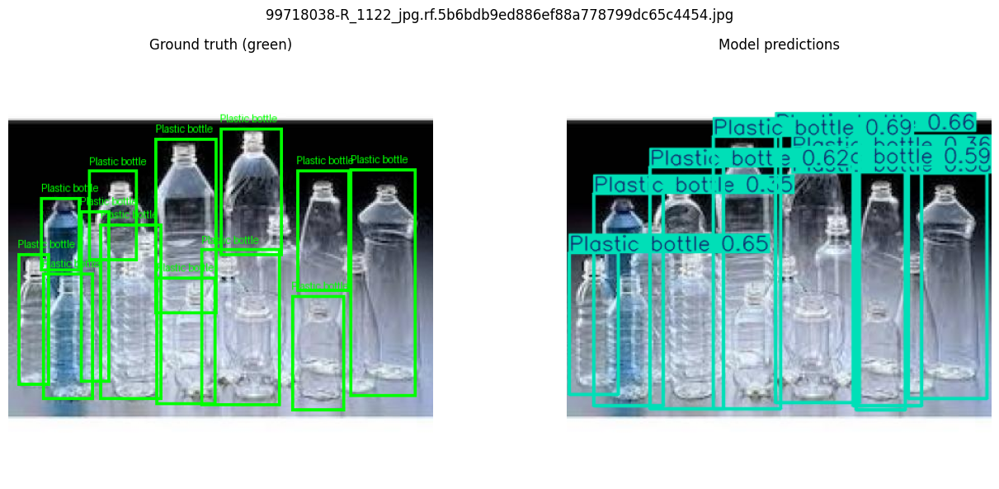

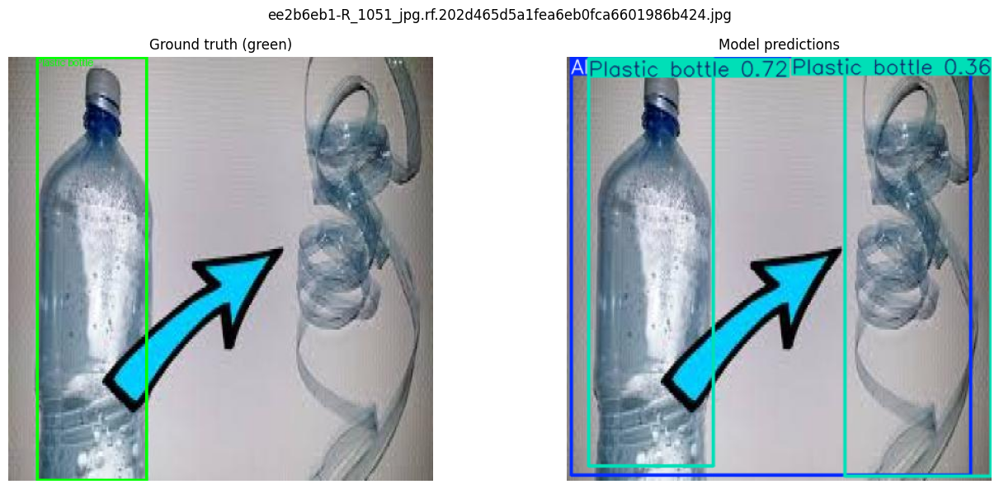

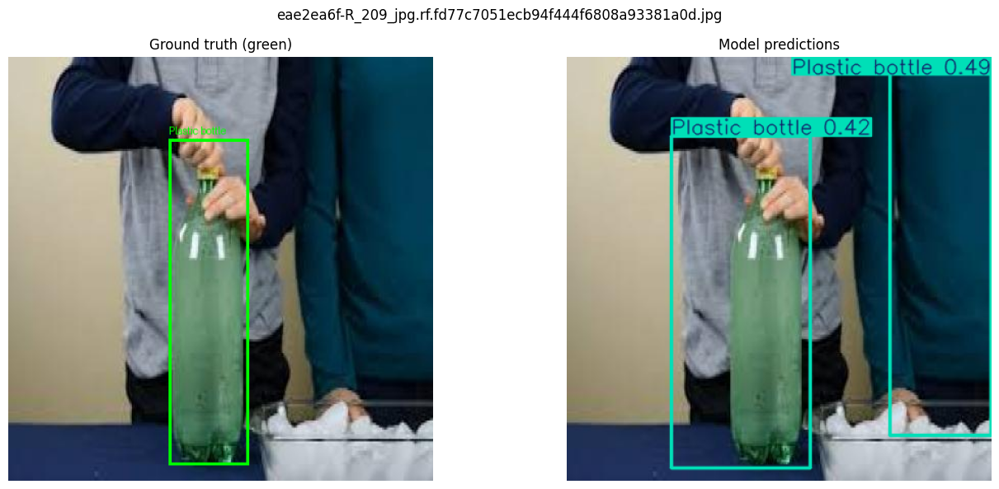

In [24]:

from pathlib import Path
from ultralytics import YOLO
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import random

DATASET = Path("/content/waste_four_classes")
DRIVE_MODEL = Path(
    "/content/drive/MyDrive/SmartWasteDetection/"
    "smart_waste_v1_best.pt"
)
LOCAL_MODEL = Path(
    "/content/runs/detect/smart_waste_v1/weights/best.pt"
)

model_path = DRIVE_MODEL if DRIVE_MODEL.exists() else LOCAL_MODEL
assert model_path.exists(), f"Model not found: {model_path}"

model = YOLO(str(model_path))

names = ["Aluminum can", "Cardboard", "Paper", "Plastic bottle"]
test_images = DATASET / "test" / "images"
test_labels = DATASET / "test" / "labels"

# Select images whose ground-truth labels contain a bottle (class 3)
bottle_images = []

for image_path in test_images.iterdir():
    label_path = test_labels / f"{image_path.stem}.txt"

    if label_path.exists():
        lines = label_path.read_text().splitlines()
        if any(line.strip() and int(line.split()[0]) == 3
               for line in lines):
            bottle_images.append(image_path)

random.seed(42)
samples = random.sample(bottle_images, min(6, len(bottle_images)))
print("Bottle-containing test images selected:", len(samples))

for image_path in samples:
    label_path = test_labels / f"{image_path.stem}.txt"
    original = Image.open(image_path).convert("RGB")
    w, h = original.size

    # Draw ground-truth boxes in green
    gt_image = original.copy()
    draw = ImageDraw.Draw(gt_image)

    for line in label_path.read_text().splitlines():
        if not line.strip():
            continue

        cls, xc, yc, bw, bh = line.split()
        cls = int(cls)
        xc, yc, bw, bh = map(float, (xc, yc, bw, bh))

        x1 = (xc - bw / 2) * w
        y1 = (yc - bh / 2) * h
        x2 = (xc + bw / 2) * w
        y2 = (yc + bh / 2) * h

        draw.rectangle((x1, y1, x2, y2), outline="lime", width=3)
        draw.text((x1, max(0, y1 - 15)), names[cls], fill="lime")

    # Run inference on the same image
    result = model.predict(
        source=str(image_path),
        conf=0.25,
        verbose=False
    )[0]

    prediction_image = Image.fromarray(result.plot()[:, :, ::-1])

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(gt_image)
    axes[0].set_title("Ground truth (green)")
    axes[1].imshow(prediction_image)
    axes[1].set_title("Model predictions")
    for ax in axes:
        ax.axis("off")

    fig.suptitle(image_path.name)
    plt.tight_layout()
    plt.show()
